# TfL bus network: routes, stops and links to rail

Phase 1 of the bus analysis. This notebook reconciles the three sources of bus route and stop
data, checks how well they match BUSTO demand, and links every bus stop to the 2024 rail network.

| Source | What it gives | Version |
|---|---|---|
| TfL bus-stops / bus-sequences feeds | LBSL stop codes (= BUSTO `stopcode`), NaPTAN ids, grid coordinates, route sequences | TfL last updated 29 Aug 2024 |
| TfL Unified API | current routes, ordered stops, WGS84 coordinates | snapshot on download date |
| BUSTO | route, direction, stop sequence and demand per year | 2023-24, 2024-25, 2025-26 |

Data comes from `data-prep/download_tfl_bus.py`; see `data/bus/README.md`. "Rail" means the TfL
rail network used in the rail analysis (Underground, Overground, DLR, Elizabeth line; no trams,
no National Rail-only stations).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import tfl_bus as B

B.RESULTS.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_colwidth', 80)
con = B.busto_con()
LATEST = 2025   # BUSTO 2025-26

## 1. Stops: do the sources agree?

In [2]:
stops = B.load_stops()
api_stops = B.load_api_stops()

# BUSTO stops with their typical-weekday boardings, per year
busto_stops = con.execute('''
    SELECT year, stopcode, any_value(stopname) AS stopname, sum(boardings) AS weekday_boardings
    FROM qhr WHERE day_type = 'Weekday' GROUP BY year, stopcode
''').df()

rows = []
for y, g in busto_stops.groupby('year'):
    m = g['stopcode'].isin(stops.index)
    rows.append({'BUSTO year': B.BUSTO_YEARS[y], 'stops': len(g), 'in feed (%)': 100 * m.mean(),
                 'weekday boardings in feed (%)': 100 * g.loc[m, 'weekday_boardings'].sum() / g['weekday_boardings'].sum(),
                 'virtual stops with demand': int(g['stopcode'].map(stops['virtual']).eq(True).sum())})
pd.DataFrame(rows).round(2)

,BUSTO year,stops,in feed (%),weekday boardings in feed (%),virtual stops with demand
0,2023-2024,19682,99.49,99.66,921
1,2024-2025,19686,99.42,99.73,922
2,2025-2026,19704,99.28,99.51,925


In [3]:
# BUSTO stops missing from the feed, busiest first (2025-26)
missing = busto_stops.query('year == @LATEST and not stopcode.isin(@stops.index)')
print(f"{len(missing)} BUSTO 2025-26 stops not in the Aug 2024 feed, "
      f"{missing.weekday_boardings.sum():,.0f} weekday boardings "
      f"({100 * missing.weekday_boardings.sum() / busto_stops.query('year == @LATEST').weekday_boardings.sum():.2f}%)")
missing.nlargest(10, 'weekday_boardings')[['stopcode', 'stopname', 'weekday_boardings']].round(0)

142 BUSTO 2025-26 stops not in the Aug 2024 feed, 25,844 weekday boardings (0.49%)


,stopcode,stopname,weekday_boardings
4893,BP1114,LEWISHAM CENTRE,3077.0
34452,BP1113,LEWISHAM CENTRE,2219.0
34347,BP1084,CROMWELL ROAD BUS STATION,2139.0
48917,BP1094,CROMWELL ROAD BUS STATION,1690.0
47477,12722,ST ANSELM'S CHURCH,1412.0
10327,20978,WEST DRAYTON STATION,1229.0
1232,161,TROCADERO / HAYMARKET,987.0
39950,210,KNIGHTSBRIDGE STATION,857.0
1109,899,SLOANE STREET / SLOANE SQUARE STATION,683.0
25317,R0703,KINGSTON STATION,537.0


Coordinates: the feed gives British National Grid easting/northing, converted to WGS84 with the
Ordnance Survey formulas in `tfl_bus.osgb_to_wgs84`. Comparing with the API's own WGS84
coordinates for the same NaPTAN stop checks both the conversion and whether stops have moved
since the feed was published.

In [4]:
j = stops.reset_index().merge(api_stops[['lat', 'lon', 'stop_name']].add_prefix('api_'),
                              left_on='naptan_id', right_index=True)
j['diff_m'] = B.haversine_m(j.lat, j.lon, j.api_lat, j.api_lon)
print(f"{len(j):,} stops in both; difference median {j.diff_m.median():.1f} m, "
      f"95th pct {j.diff_m.quantile(.95):.0f} m, over 50 m: {(j.diff_m > 50).sum()}")
j.nlargest(8, 'diff_m')[['stopcode', 'naptan_id', 'stop_name', 'api_stop_name', 'diff_m']].round(0)

19,782 stops in both; difference median 1.0 m, 95th pct 34 m, over 50 m: 536


,stopcode,naptan_id,stop_name,api_stop_name,diff_m
18822,HC679,490002166HN,Hail & Ride Brookland Hill,Coltsfoot Path,28222.0
18005,H0568,490013611E,Hail & Ride Oakhill Road,Oakhill Road Sutton,6123.0
3636,11393,490006943N,Greenwood Centre,Greenwood Centre,997.0
19368,OC251,40004410134A,Ricketts Hill Road / Manor House,Ricketts Hill Road / Manor House,699.0
19367,OC250,40004410805F,Cudham Hill,Cudham Hill,652.0
19366,OC248,40004410805D,Cudham Road,Cudham Road,576.0
11410,34251,490000148K,Monument Station <>,Monument Station,515.0
19369,OC252,40004410805G,Tatsfield Green,Tatsfield Green,502.0


The median difference of about 1 m confirms the conversion. The large differences are stops whose
NaPTAN id now points somewhere else (renamed or relocated stops), so **the feed's coordinates are
used throughout**: they match the LBSL codes BUSTO uses.

## 2. Routes

In [5]:
busto_routes = con.execute('SELECT DISTINCT year, route FROM qhr').df()
api_routes = set(B.load_api_routes()['route_id'].str.upper())
feed_seq = B.load_feed_sequences()
feed_routes = set(feed_seq['route'].str.upper())

by_year = {y: set(g['route'].str.upper()) for y, g in busto_routes.groupby('year')}
summary = pd.DataFrame({
    'routes': {**{f'BUSTO {B.BUSTO_YEARS[y]}': len(s) for y, s in by_year.items()},
               'feed (Aug 2024)': len(feed_routes), 'API (current)': len(api_routes)},
})
summary

,routes
BUSTO 2023-2024,603
BUSTO 2024-2025,604
BUSTO 2025-2026,606
feed (Aug 2024),800
API (current),677


In [6]:
latest = by_year[LATEST]
changes = pd.DataFrame({
    'BUSTO 2023-24 -> 2025-26 added': [', '.join(sorted(by_year[LATEST] - by_year[2023]))],
    'BUSTO 2023-24 -> 2025-26 removed': [', '.join(sorted(by_year[2023] - by_year[LATEST]))],
    'in API, not in BUSTO 2025-26': [', '.join(sorted(api_routes - latest, key=lambda r: (B.route_type(r), r)))],
    'in BUSTO 2025-26, not in API': [', '.join(sorted(latest - api_routes))],
}).T.rename(columns={0: 'routes'})
changes

,routes
BUSTO 2023-24 -> 2025-26 added,"310, 439, BL1, N263, S2, SL1, SL10, SL2, SL3, SL4, SL5"
BUSTO 2023-24 -> 2025-26 removed,"118, 347, 414, 455, 497, 549, N271, R6"
"in API, not in BUSTO 2025-26","SCS, N118, N472, 10, 969, 601, 602, 603, 606, 608, 612, 613, 616, 617, 618, ..."
"in BUSTO 2025-26, not in API","283, 349, 472, 533"


In [7]:
types = pd.DataFrame({
    'BUSTO 2025-26': pd.Series([B.route_type(r) for r in latest]).value_counts(),
    'API': pd.Series([B.route_type(r) for r in api_routes]).value_counts(),
}).fillna(0).astype(int)
types

,BUSTO 2025-26,API
letter prefix,97,98
night,62,64
numbered,437,435
school,0,68
superloop,10,12


BUSTO covers the regular network, including night routes and the Superloop (`SL`) express
routes, but **no school routes** (6xx). The API lists every route currently running.

In [8]:
print('SL routes in BUSTO:', sorted(r for r in latest if r.startswith('SL')))
print('Night routes in BUSTO 2025-26:', sum(r.startswith('N') for r in latest))

SL routes in BUSTO: ['SL1', 'SL10', 'SL2', 'SL3', 'SL4', 'SL5', 'SL6', 'SL7', 'SL8', 'SL9']
Night routes in BUSTO 2025-26: 62


### Route geometry from BUSTO

BUSTO itself lists every stop on every route and direction in order (`stopsequence`), so it defines
the network that carried the measured demand. Route length is the sum of straight-line distances
between consecutive stops (a lower bound on road distance). Superloop routes are express services,
so their stops are far apart.

In [9]:
seq = con.execute('''
    SELECT DISTINCT year, route, direction, stopsequence, stopcode FROM qhr WHERE day_type = 'Weekday'
''').df()
seq = seq.join(stops[['lat', 'lon', 'virtual']], on='stopcode')

# A route-direction where one sequence number has two different stops mixes two route variants
# (a route change during the year, averaged together); its length cannot be computed from the order.
dup = (seq.groupby(['year', 'route', 'direction'])['stopsequence'].agg(lambda s: s.duplicated().any()))
print('route-directions with mixed variants:', dup[dup].reset_index()[['year', 'route', 'direction']].values.tolist())

def route_shape(g):
    if g['stopsequence'].duplicated().any():
        return pd.Series({'stops': g['stopcode'].nunique(), 'length_km': np.nan, 'mean_spacing_m': np.nan})
    g = g.sort_values('stopsequence').dropna(subset=['lat'])
    d = B.haversine_m(g.lat.values[:-1], g.lon.values[:-1], g.lat.values[1:], g.lon.values[1:])
    return pd.Series({'stops': len(g), 'length_km': d.sum() / 1000,
                      'mean_spacing_m': d.mean() if len(d) else np.nan})

shape = (seq.query('year == @LATEST').groupby(['route', 'direction']).apply(route_shape, include_groups=False)
         .groupby('route').mean())
shape['type'] = [B.route_type(r) for r in shape.index]
shape.groupby('type')[['stops', 'length_km', 'mean_spacing_m']].median().round(1).assign(
    routes=shape.groupby('type').size())

route-directions with mixed variants: [[2023, '229', 2], [2023, '313', 1], [2023, '328', 1], [2023, '466', 2], [2023, '467', 1], [2023, '467', 2], [2023, '63', 2], [2023, 'B12', 1], [2023, 'EL3', 2], [2023, 'K1', 2], [2023, 'K3', 1], [2025, '102', 2]]


,stops,length_km,mean_spacing_m,routes
type,,,,
letter prefix,37.0,11.1,310.1,97
night,60.2,18.8,295.0,62
numbered,41.0,12.0,299.5,437
superloop,13.8,15.7,1126.2,10


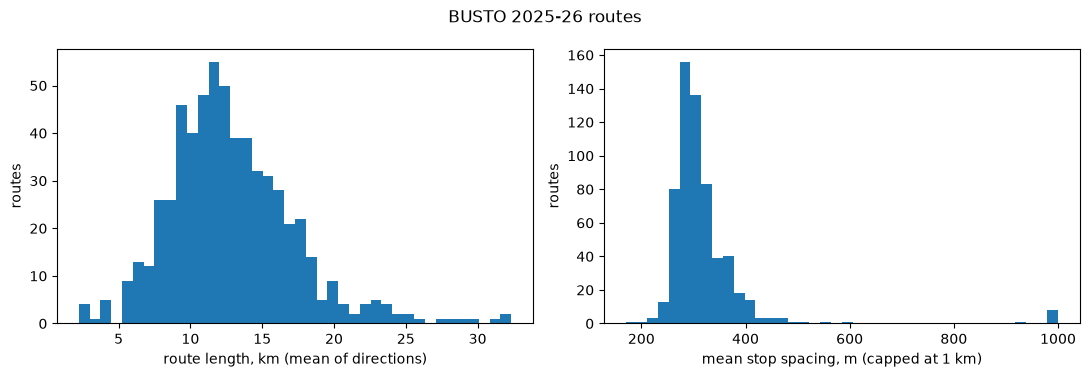

            type  stops  length_km
route                             
N199       night  111.0       32.3
N89        night  105.5       32.1
SL7    superloop   13.5       30.9
N9         night   83.0       29.4
N68        night   96.5       28.7


In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
shape.length_km.plot.hist(bins=40, ax=axs[0]); axs[0].set_xlabel('route length, km (mean of directions)')
shape.mean_spacing_m.clip(upper=1000).plot.hist(bins=40, ax=axs[1]); axs[1].set_xlabel('mean stop spacing, m (capped at 1 km)')
for ax in axs: ax.set_ylabel('routes')
plt.suptitle('BUSTO 2025-26 routes'); plt.tight_layout(); plt.show()
print(shape.nlargest(5, 'length_km')[['type', 'stops', 'length_km']].round(1))

### Do BUSTO and the API describe the same routes?

Stop sets per route are compared by NaPTAN id (Jaccard similarity: shared stops / all stops,
both directions together), because the two sources label directions differently.

In [11]:
bseq = seq.query('year == @LATEST').join(stops['naptan_id'], on='stopcode')
b_sets = bseq.dropna(subset=['naptan_id']).groupby(bseq['route'].str.upper())['naptan_id'].agg(set)
aseq = B.load_api_sequences()
a_sets = aseq.groupby(aseq['route_id'].str.upper())['naptan_id'].agg(set)
common = b_sets.index.intersection(a_sets.index)
jac = pd.Series({r: len(b_sets[r] & a_sets[r]) / len(b_sets[r] | a_sets[r]) for r in common})
print(f"{len(common)} routes in both. Jaccard similarity: median {jac.median():.2f}; "
      f">= 0.9 for {100 * (jac >= .9).mean():.0f}% of routes; < 0.5 for {(jac < .5).sum()} routes")
jac.nsmallest(10).round(2).rename('jaccard').to_frame()

602 routes in both. Jaccard similarity: median 0.99; >= 0.9 for 89% of routes; < 0.5 for 2 routes


,jaccard
209,0.34
464,0.41
485,0.52
310,0.53
380,0.56
379,0.59
72,0.59
259,0.61
19,0.66
38,0.69


Most routes match closely. Routes with low similarity were rerouted or restructured between the
2025-26 BUSTO year and the API snapshot. For demand analysis, BUSTO's own sequences are used;
the API is used only where a current network is needed.

## 3. Bus stops and rail stations

In [12]:
rail = B.rail_stations()
phys = stops[~stops['virtual']].copy()          # virtual stops are timing points, not boarding places
phys = phys.join(B.nearest_rail(phys, rail))
print(f"{len(rail)} rail stations, {len(phys):,} physical bus stops")

w = busto_stops.query('year == @LATEST').set_index('stopcode')['weekday_boardings']
phys['weekday_boardings'] = w.reindex(phys.index).fillna(0)

dist_rows = []
for r in B.WALK_RADII_M + [1000, 2000]:
    near = phys['dist_m'] <= r
    dist_rows.append({'within (m)': r, 'stops (%)': 100 * near.mean(),
                      'weekday boardings (%)': 100 * phys.loc[near, 'weekday_boardings'].sum() / phys['weekday_boardings'].sum()})
dist_summary = pd.DataFrame(dist_rows).round(1)
dist_summary.to_csv(B.RESULTS / 'stop_rail_distance_summary.csv', index=False)
dist_summary

418 rail stations, 18,823 physical bus stops


,within (m),stops (%),weekday boardings (%)
0,200,9.5,27.4
1,400,21.4,43.1
2,800,42.2,62.5
3,1000,49.9,68.9
4,2000,71.0,85.4


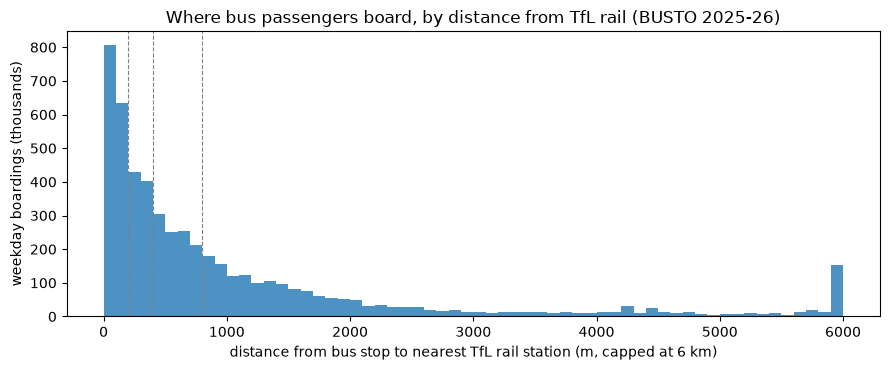

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.arange(0, 6001, 100)
ax.hist(phys.dist_m.clip(upper=6000), bins=bins, weights=phys.weekday_boardings / 1e3, alpha=.8)
for r in B.WALK_RADII_M: ax.axvline(r, color='grey', lw=.8, ls='--')
ax.set_xlabel('distance from bus stop to nearest TfL rail station (m, capped at 6 km)')
ax.set_ylabel('weekday boardings (thousands)')
ax.set_title('Where bus passengers board, by distance from TfL rail (BUSTO 2025-26)')
plt.tight_layout(); plt.show()

Links between rail stations and bus stops at the default 400 m walk (about five minutes).
The 200 m and 800 m versions are kept for sensitivity checks in later phases.

In [14]:
links = {r: B.bus_rail_links(phys, rail, r) for r in B.WALK_RADII_M}
routes_at_stop = (seq.query('year == @LATEST').groupby('stopcode')['route'].agg(lambda s: set(s.str.upper())))

def station_table(lk):
    g = lk.join(routes_at_stop.rename('routes'), on='stopcode').join(phys['weekday_boardings'], on='stopcode')
    return g.groupby('station').agg(
        bus_stops=('stopcode', 'nunique'),
        bus_routes=('routes', lambda s: len(set().union(*[x for x in s if isinstance(x, set)]))),
        weekday_boardings_within=('weekday_boardings', 'sum'))

conn = rail.join(station_table(links[B.WALK_M]))
cols = ['bus_stops', 'bus_routes', 'weekday_boardings_within']
conn[cols] = conn[cols].fillna(0).astype(int)
for r in (200, 800):
    conn[f'bus_routes_{r}m'] = station_table(links[r])['bus_routes'].reindex(conn.index).fillna(0).astype(int)
conn.to_csv(B.RESULTS / 'rail_station_bus_connectivity.csv', index_label='station')
# weekday_boardings_within: bus boardings at stops within 400 m (catchments of nearby stations overlap)
conn.nlargest(12, 'bus_routes')[['lines', 'bus_stops', 'bus_routes', 'bus_routes_200m', 'bus_routes_800m', 'weekday_boardings_within']]

,lines,bus_stops,bus_routes,bus_routes_200m,bus_routes_800m,weekday_boardings_within
station,,,,,,
Covent Garden,Piccadilly,12,48,0,70,19066
Leicester Square,Northern; Piccadilly,18,43,13,72,22083
Charing Cross,Bakerloo; Northern,22,41,39,63,17808
Embankment,Bakerloo; District; H&C and Circle; Northern,15,41,0,60,12761
Elephant & Castle,Bakerloo; Northern,24,36,36,41,43936
Temple,District; H&C and Circle,12,33,0,44,13933
Waterloo,Bakerloo; Jubilee; Northern; Waterloo & City,20,31,17,46,22655
Tottenham Court Road,Central; Elizabeth Line; Northern,16,30,30,55,22637
Piccadilly Circus,Bakerloo; Piccadilly,17,29,21,66,17673


In [15]:
none = conn.query('bus_routes == 0')
print(f"{len(none)} rail stations with no BUSTO bus route within {B.WALK_M} m "
      "(mostly outside Greater London, where London Buses do not run):")
none[['lines', 'bus_routes_800m']].sort_values('bus_routes_800m')

23 rail stations with no BUSTO bus route within 400 m (mostly outside Greater London, where London Buses do not run):


,lines,bus_routes_800m
station,,
Amersham,Metropolitan,0
Theydon Bois,Central,0
Taplow,Elizabeth Line,0
Shenfield,Elizabeth Line,0
Rickmansworth,Metropolitan,0
Reading,Elizabeth Line,0
Moor Park,Metropolitan,0
Maidenhead,Elizabeth Line,0
Langley,Elizabeth Line,0


## 4. Map: bus demand and distance from rail

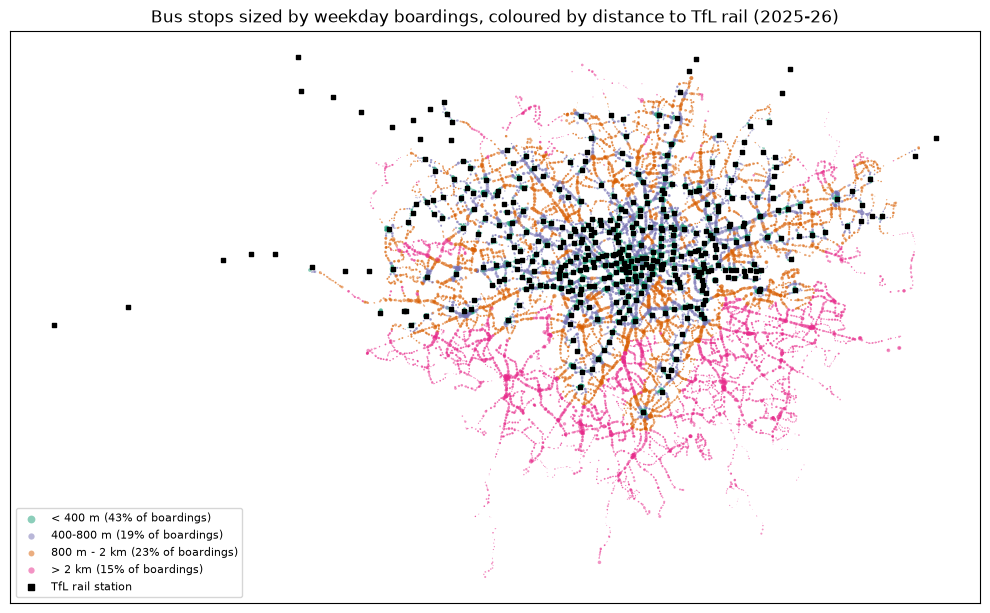

In [16]:
bands = [0, 400, 800, 2000, np.inf]
labels = ['< 400 m', '400-800 m', '800 m - 2 km', '> 2 km']
phys['band'] = pd.cut(phys['dist_m'], bands, labels=labels, right=False)
colors = dict(zip(labels, ['#1b9e77', '#7570b3', '#d95f02', '#e7298a']))

fig, ax = plt.subplots(figsize=(10, 8.5))
for lab in labels:
    p = phys[(phys.band == lab) & (phys.weekday_boardings > 0)]
    ax.scatter(p.lon, p.lat, s=np.sqrt(p.weekday_boardings) / 4, color=colors[lab], alpha=.5, lw=0,
               label=f'{lab} ({100 * p.weekday_boardings.sum() / phys.weekday_boardings.sum():.0f}% of boardings)')
ax.scatter(rail.lon, rail.lat, s=6, color='black', marker='s', label='TfL rail station')
ax.set_aspect(1 / np.cos(np.radians(51.5)))
ax.set_title('Bus stops sized by weekday boardings, coloured by distance to TfL rail (2025-26)')
ax.legend(loc='lower left', fontsize=8, markerscale=1.5); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 5. Save linked stop table

In [17]:
out = phys[['sms_code', 'naptan_id', 'stop_name', 'stop_area', 'lat', 'lon',
            'nearest_station', 'dist_m', 'weekday_boardings']].copy()
out['weekday_boardings'] = out['weekday_boardings'].round(1)
out.to_parquet(B.PROCESSED / 'bus-stops-linked.parquet')           # local (large)
links[B.WALK_M].to_csv(B.RESULTS / 'bus_rail_links_400m.csv', index=False)
shape.round(2).to_csv(B.RESULTS / 'route_shape_2025.csv', index_label='route')
print('saved:', [p.name for p in B.RESULTS.iterdir()])

saved: ['bus_rail_links_400m.csv', 'stop_rail_distance_summary.csv', 'rail_station_bus_connectivity.csv', 'route_shape_2025.csv']
